# IT Employee Attrition Analysis (Simulated Data)

In this notebook I analyze employee attrition using Python (Pandas and Matplotlib).

**Note:** The dataset is simulated. I created it with Python (see `IT_Employee_Attrition_Data_Generation.ipynb`), so these results are for practice and are not from a real company.

**Goal:** Find out which employee groups leave the company the most.

I compare the **attrition rate (%)** of each group, not the raw count. A bigger group always has more people leaving, so the count can give a wrong picture.

In [7]:
# Import the libraries
import os
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
# Make a folder to save the charts
os.makedirs('charts', exist_ok=True)

## 1. Load the data

In [9]:
# Read the csv file
df = pd.read_csv('it_employee_attrition_dataset.csv')

# Show the first 5 rows
df.head()

,Employee_ID,Department,Total_Experience_Years,Salary_LPA,Years_Since_Last_Promotion,Work_Mode,Distance_From_Home_KM,Overtime,Attrition
0,1001,IT,12,20.25,3,WFO,40,No,Yes
1,1002,Operations,8,15.27,0,WFO,10,No,No
2,1003,HR,3,8.20,1,WFH,22,Yes,No
3,1004,Sales,8,14.61,5,WFO,13,Yes,Yes
4,1005,IT,5,11.19,1,WFO,30,No,No


## 2. Check the data

In [10]:
# Number of rows and columns
print(df.shape)

# Column names and data types
df.info()

(1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_ID                 1000 non-null   int64  
 1   Department                  1000 non-null   object 
 2   Total_Experience_Years      1000 non-null   int64  
 3   Salary_LPA                  1000 non-null   float64
 4   Years_Since_Last_Promotion  1000 non-null   int64  
 5   Work_Mode                   1000 non-null   object 
 6   Distance_From_Home_KM       1000 non-null   int64  
 7   Overtime                    1000 non-null   object 
 8   Attrition                   1000 non-null   object 
dtypes: float64(1), int64(4), object(4)
memory usage: 70.4+ KB


In [11]:
# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Employee_ID                   0
Department                    0
Total_Experience_Years        0
Salary_LPA                    0
Years_Since_Last_Promotion    0
Work_Mode                     0
Distance_From_Home_KM         0
Overtime                      0
Attrition                     0
dtype: int64
Duplicate rows: 0


In [12]:
# Basic statistics of the number columns
df.describe()

,Employee_ID,Total_Experience_Years,Salary_LPA,Years_Since_Last_Promotion,Distance_From_Home_KM
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,1500.500000,6.538000,12.631900,2.57200,22.611000
std,288.819436,3.492098,4.906326,1.71048,12.124962
min,1001.000000,1.000000,3.900000,0.00000,2.000000
25%,1250.750000,3.000000,8.337500,1.00000,13.000000
50%,1500.500000,7.000000,12.740000,3.00000,22.000000
75%,1750.250000,10.000000,16.765000,4.00000,33.000000
max,2000.000000,12.000000,21.290000,5.00000,44.000000


The data has 1000 rows and 9 columns. There are no missing values and no duplicate rows, so no cleaning is needed.

## 3. Prepare the data

In [13]:
# Make a new column: 1 if the employee left, 0 if the employee stayed
# The average of this column gives the attrition rate
df['Attrition_Flag'] = df['Attrition'].map({'Yes': 1, 'No': 0})

In [14]:
# Group employees by experience
df['Experience_Level'] = pd.cut(df['Total_Experience_Years'],
                                bins=[0, 2, 7, 15],
                                labels=['Entry (0-2 yrs)', 'Mid (3-7 yrs)', 'Senior (8+ yrs)'])

# Group employees by salary
df['Salary_Band'] = pd.cut(df['Salary_LPA'],
                           bins=[0, 5.99, 12, 30],
                           labels=['Low (below 6 LPA)', 'Medium (6-12 LPA)', 'High (above 12 LPA)'])

# Group employees by distance from home
df['Distance_Group'] = pd.cut(df['Distance_From_Home_KM'],
                              bins=[0, 10, 20, 30, 50],
                              labels=['1-10 km', '11-20 km', '21-30 km', '31+ km'])

## 4. Overall attrition

In [15]:
total_employees = len(df)
employees_left = df['Attrition_Flag'].sum()
overall_rate = df['Attrition_Flag'].mean() * 100

print("Total employees:", total_employees)
print("Employees left:", employees_left)
print("Attrition rate:", round(overall_rate, 2), "%")

Total employees: 1000
Employees left: 257
Attrition rate: 25.7 %


## 5. Attrition rate by Department

In [16]:
# Number of employees in each department
print(df['Department'].value_counts())

# Attrition rate (%) of each department
dept_rate = df.groupby('Department')['Attrition_Flag'].mean() * 100
dept_rate = dept_rate.sort_values(ascending=False)
print(dept_rate.round(2))

Department
IT            461
Sales         251
Operations    199
HR             89
Name: count, dtype: int64
Department
Sales         32.67
Operations    27.64
IT            22.56
HR            17.98
Name: Attrition_Flag, dtype: float64


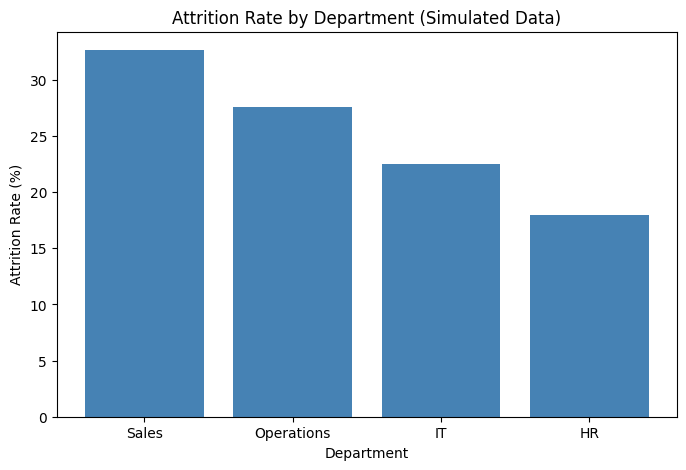

In [17]:
plt.figure(figsize=(8, 5))
plt.bar(dept_rate.index, dept_rate.values, color='steelblue')
plt.title('Attrition Rate by Department (Simulated Data)')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/01_department.png')
plt.show()

## 6. Attrition rate by Work Mode

In [18]:
print(df['Work_Mode'].value_counts())

work_rate = df.groupby('Work_Mode')['Attrition_Flag'].mean() * 100
work_rate = work_rate.sort_values(ascending=False)
print(work_rate.round(2))

Work_Mode
Hybrid    409
WFO       318
WFH       273
Name: count, dtype: int64
Work_Mode
WFO       31.45
WFH       26.37
Hybrid    20.78
Name: Attrition_Flag, dtype: float64


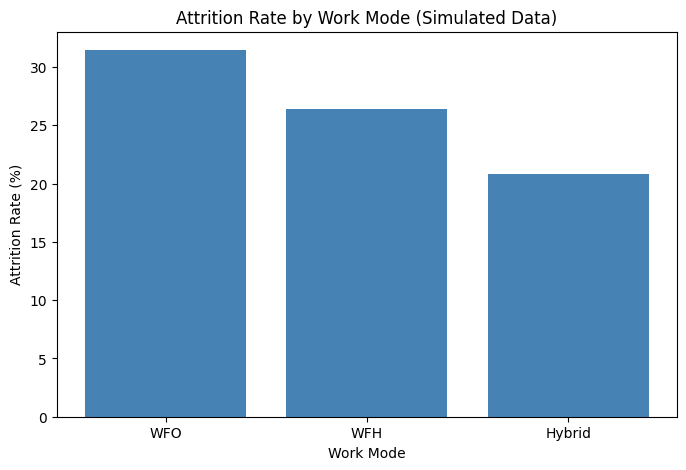

In [19]:
plt.figure(figsize=(8, 5))
plt.bar(work_rate.index, work_rate.values, color='steelblue')
plt.title('Attrition Rate by Work Mode (Simulated Data)')
plt.xlabel('Work Mode')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/02_work_mode.png')
plt.show()

## 7. Attrition rate by Overtime

In [20]:
print(df['Overtime'].value_counts())

overtime_rate = df.groupby('Overtime')['Attrition_Flag'].mean() * 100
print(overtime_rate.round(2))

Overtime
No     642
Yes    358
Name: count, dtype: int64
Overtime
No     19.31
Yes    37.15
Name: Attrition_Flag, dtype: float64


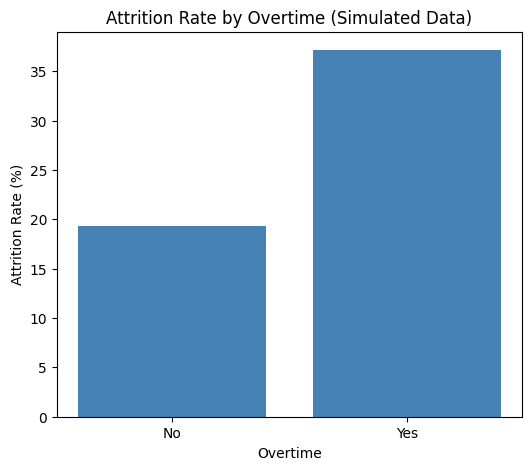

In [21]:
plt.figure(figsize=(6, 5))
plt.bar(overtime_rate.index, overtime_rate.values, color='steelblue')
plt.title('Attrition Rate by Overtime (Simulated Data)')
plt.xlabel('Overtime')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/03_overtime.png')
plt.show()

## 8. Attrition rate by Experience

In [22]:
print(df['Experience_Level'].value_counts())

experience_rate = df.groupby('Experience_Level', observed=True)['Attrition_Flag'].mean() * 100
print(experience_rate.round(2))

Experience_Level
Senior (8+ yrs)    424
Mid (3-7 yrs)      399
Entry (0-2 yrs)    177
Name: count, dtype: int64
Experience_Level
Entry (0-2 yrs)    45.20
Mid (3-7 yrs)      21.05
Senior (8+ yrs)    21.93
Name: Attrition_Flag, dtype: float64


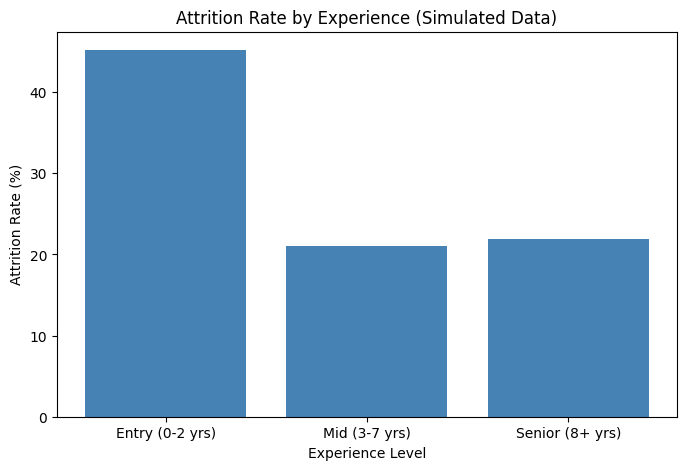

In [23]:
plt.figure(figsize=(8, 5))
plt.bar(experience_rate.index, experience_rate.values, color='steelblue')
plt.title('Attrition Rate by Experience (Simulated Data)')
plt.xlabel('Experience Level')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/04_experience.png')
plt.show()

## 9. Attrition rate by Salary

In [24]:
print(df['Salary_Band'].value_counts())

salary_rate = df.groupby('Salary_Band', observed=True)['Attrition_Flag'].mean() * 100
print(salary_rate.round(2))

Salary_Band
High (above 12 LPA)    545
Medium (6-12 LPA)      338
Low (below 6 LPA)      117
Name: count, dtype: int64
Salary_Band
Low (below 6 LPA)      51.28
Medium (6-12 LPA)      22.49
High (above 12 LPA)    22.20
Name: Attrition_Flag, dtype: float64


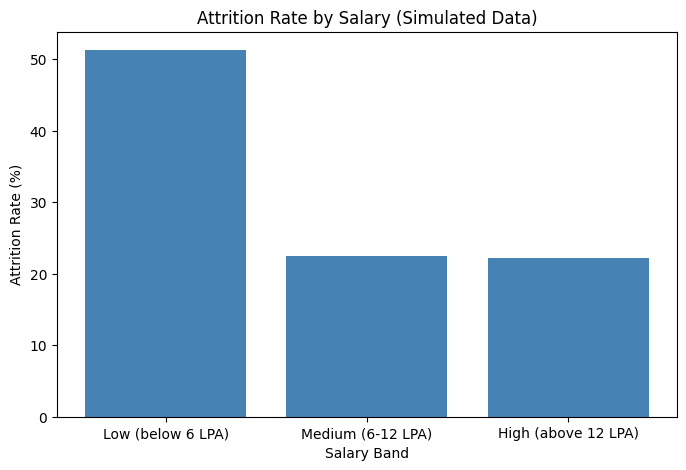

In [25]:
plt.figure(figsize=(8, 5))
plt.bar(salary_rate.index, salary_rate.values, color='steelblue')
plt.title('Attrition Rate by Salary (Simulated Data)')
plt.xlabel('Salary Band')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/05_salary.png')
plt.show()

## 10. Attrition rate by Years Since Last Promotion

In [26]:
print(df['Years_Since_Last_Promotion'].value_counts().sort_index())

promotion_rate = df.groupby('Years_Since_Last_Promotion')['Attrition_Flag'].mean() * 100
print(promotion_rate.round(2))

Years_Since_Last_Promotion
0    166
1    147
2    156
3    185
4    172
5    174
Name: count, dtype: int64
Years_Since_Last_Promotion
0    24.70
1    23.13
2    19.23
3    23.78
4    28.49
5    33.91
Name: Attrition_Flag, dtype: float64


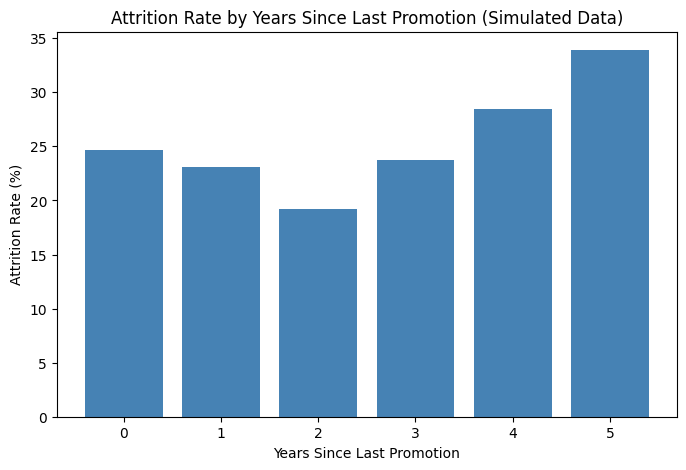

In [27]:
plt.figure(figsize=(8, 5))
plt.bar(promotion_rate.index, promotion_rate.values, color='steelblue')
plt.title('Attrition Rate by Years Since Last Promotion (Simulated Data)')
plt.xlabel('Years Since Last Promotion')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/06_promotion.png')
plt.show()

## 11. Attrition rate by Distance from Home

In [28]:
print(df['Distance_Group'].value_counts())

distance_rate = df.groupby('Distance_Group', observed=True)['Attrition_Flag'].mean() * 100
print(distance_rate.round(2))

Distance_Group
31+ km      291
11-20 km    253
21-30 km    249
1-10 km     207
Name: count, dtype: int64
Distance_Group
1-10 km     23.19
11-20 km    25.30
21-30 km    24.90
31+ km      28.52
Name: Attrition_Flag, dtype: float64


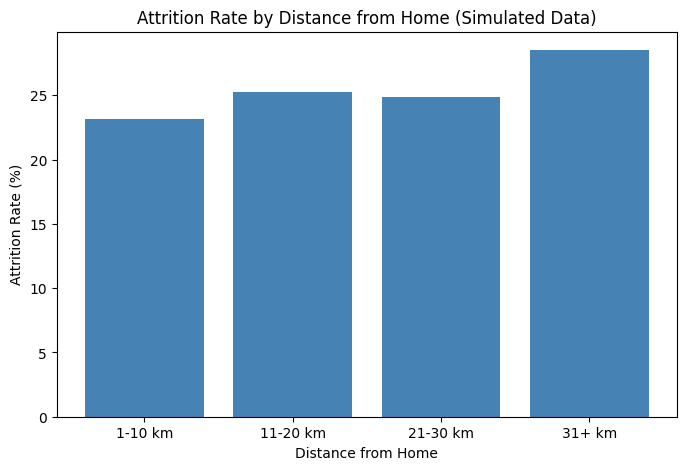

In [29]:
plt.figure(figsize=(8, 5))
plt.bar(distance_rate.index, distance_rate.values, color='steelblue')
plt.title('Attrition Rate by Distance from Home (Simulated Data)')
plt.xlabel('Distance from Home')
plt.ylabel('Attrition Rate (%)')
plt.savefig('charts/07_distance.png')
plt.show()

## 12. Overtime and Experience together

In [30]:
# Attrition rate for each overtime and experience group
both_rate = df.groupby(['Overtime', 'Experience_Level'], observed=True)['Attrition_Flag'].mean() * 100
print(both_rate.round(2))

Overtime  Experience_Level
No        Entry (0-2 yrs)     38.39
          Mid (3-7 yrs)       15.16
          Senior (8+ yrs)     15.38
Yes       Entry (0-2 yrs)     56.92
          Mid (3-7 yrs)       30.32
          Senior (8+ yrs)     35.51
Name: Attrition_Flag, dtype: float64


## 13. Key Findings

The overall attrition rate is **25.7%** (257 out of 1000 employees).

1. **Salary:** Employees earning below 6 LPA have the highest attrition rate (51.3%). The Medium (22.5%) and High (22.2%) salary groups are almost the same.
2. **Experience:** Entry-level employees (0-2 years) leave the most (45.2%). Mid-level (21.1%) and Senior (21.9%) employees are much lower. Salary depends on experience in this data, so these two findings are connected.
3. **Overtime:** Employees who do overtime leave more (37.2%) than employees who do not (19.3%). Entry-level employees with overtime have the highest rate (56.9%).
4. **Department:** Sales has the highest rate (32.7%), then Operations (27.6%), IT (22.6%) and HR (18.0%). IT has the most employees leaving in numbers (104), but only because IT is the biggest department.
5. **Work Mode:** WFO has the highest rate (31.5%), then WFH (26.4%). Hybrid is the lowest (20.8%).
6. **Promotion:** Attrition goes up after 4 to 5 years without a promotion (28.5% and 33.9%).
7. **Distance:** Distance has only a small effect. The rate is 28.5% for employees living 31+ km away, and about 23% to 25% for the others.

**Limitations:** The data is simulated, so these patterns come from the rules I used to create the data. HR has only 89 employees, so its result is less reliable. This is a basic analysis and I did not use any statistical tests.